<h1>Imports</h1>

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram,plot_bloch_multivector
from qiskit.circuit.library import DiagonalGate
import numpy as np
from qiskit_ibm_runtime.options_models import simulator


<h1>Initialazation Function</h1>

In [2]:
def initialize_s(qc, qubits):
    for q in qubits:
        qc.h(q)
    return qc

<h1>Diffuser</h1>

In [3]:
def diffuser(nqubits):
    qc = QuantumCircuit(nqubits)

    for qubit in range(nqubits):
        qc.h(qubit)

    for qubit in range(nqubits):
        qc.z(qubit)

    qc.cz(list(range(nqubits - 1)), nqubits - 1)

    for qubit in range(nqubits):
        qc.h(qubit)

    return qc.to_gate()

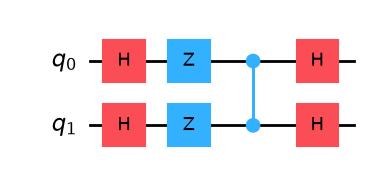

In [13]:
diffuser(2).definition.draw("mpl")

<h1>Gover's Algorithm</h1>

In [14]:

def grover_problem_oracle(n, variant=0, print_solutions=False):
    np.random.seed(variant)

    if n < 3:
        nsolutions = 1
    else:
        nsolutions = np.random.randint(1, np.ceil(2**n/4))

    diagonal_elements = [-1]*nsolutions + [1]*((2**n)-nsolutions)
    np.random.shuffle(diagonal_elements)

    oracle_gate = DiagonalGate(diagonal_elements)
    oracle_gate.name = "Oracle\n=%i, var=%i" % (n, variant)

    if print_solutions:
        print("Solutions:")
        for idx, e in enumerate(diagonal_elements):
            if e < 1:
                print("|%s>" % format(idx, "0%ib" % n))

    return oracle_gate

Solutions:
|101>


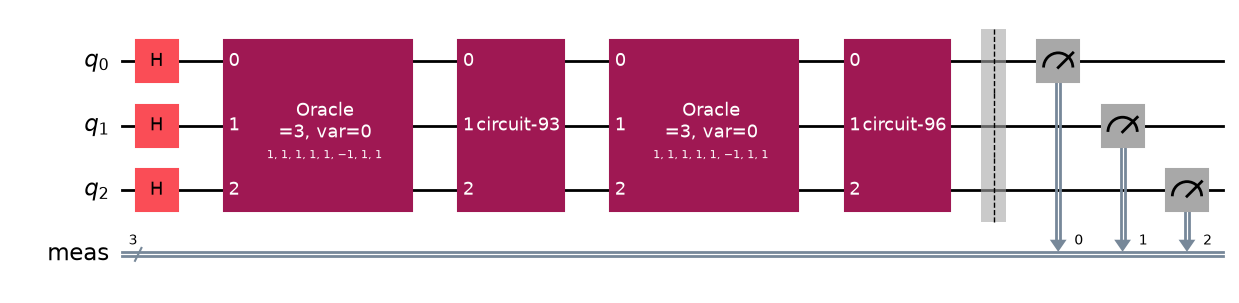

In [15]:
n = 3

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,[0, 1, 2])

grover_circuit.append(oracle, [0, 1, 2])
grover_circuit.append(diffuser(n), [0, 1, 2])

grover_circuit.append(oracle, [0, 1, 2])
grover_circuit.append(diffuser(n), [0, 1, 2])

grover_circuit.measure_all()

grover_circuit.draw("mpl")

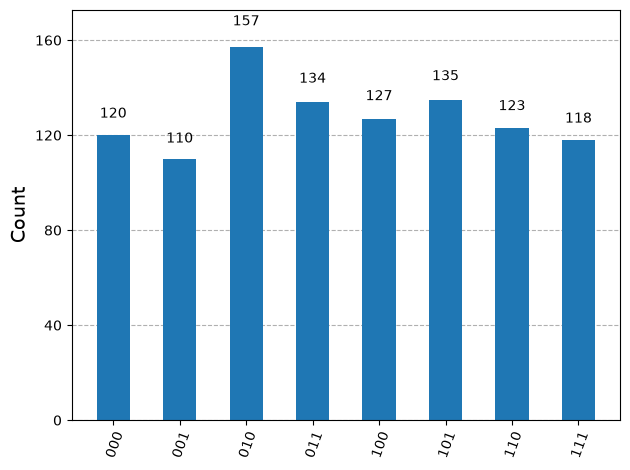

In [16]:
simulator = AerSimulator()

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shot=1000)

plot_histogram(job.result().get_counts())

<h1>Two Slution Grover</h1>

In [19]:

def grover_problem_oracle(n, variant=0, print_solutions=False):
    np.random.seed(variant)

    '''if n < 3:
        nsolutions = 2
    else:
        nsolutions = np.random.randint(1, np.ceil(2**n/4))'''

    nsolutions = 2

    diagonal_elements = [-1]*nsolutions + [1]*((2**n)-nsolutions)
    np.random.shuffle(diagonal_elements)

    oracle_gate = DiagonalGate(diagonal_elements)
    oracle_gate.name = "Oracle\n=%i, var=%i" % (n, variant)

    if print_solutions:
        print("Solutions:")
        for idx, e in enumerate(diagonal_elements):
            if e < 1:
                print("|%s>" % format(idx, "0%ib" % n))

    return oracle_gate

Solutions:
|010>
|101>


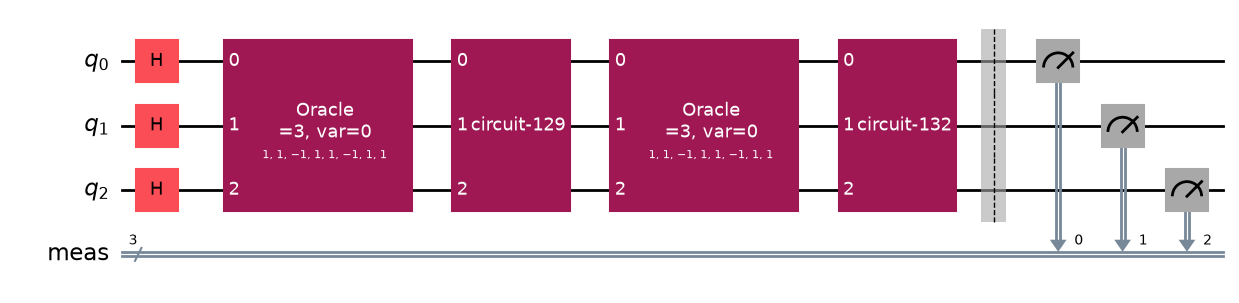

In [20]:
n = 3

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,[0, 1, 2])

grover_circuit.append(oracle, [0, 1, 2])
grover_circuit.append(diffuser(n), [0, 1, 2])

grover_circuit.append(oracle, [0, 1, 2])
grover_circuit.append(diffuser(n), [0, 1, 2])

grover_circuit.measure_all()

grover_circuit.draw("mpl")

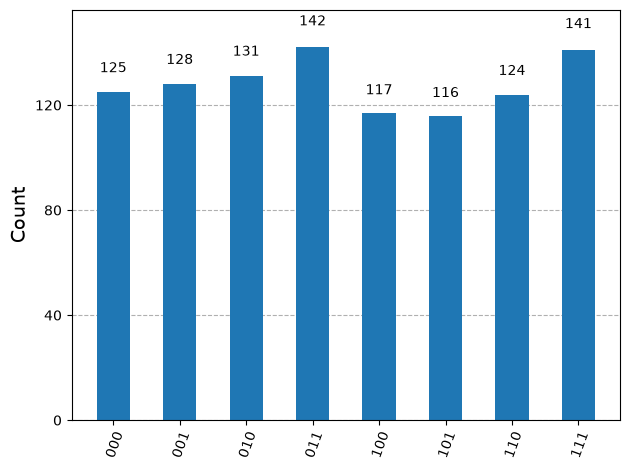

In [21]:
simulator = AerSimulator()

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shot=1000)

plot_histogram(job.result().get_counts())

Solutions:
|10>
|11>


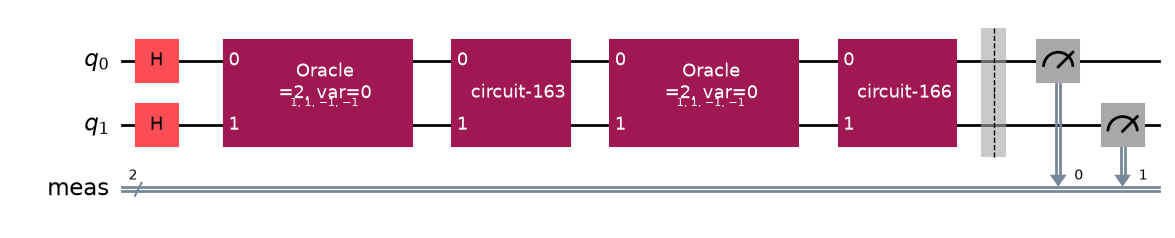

In [22]:
n = 2

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,[0, 1])

grover_circuit.append(oracle, [0, 1])
grover_circuit.append(diffuser(n), [0, 1])

grover_circuit.append(oracle, [0, 1])
grover_circuit.append(diffuser(n), [0, 1])

grover_circuit.measure_all()

grover_circuit.draw("mpl")

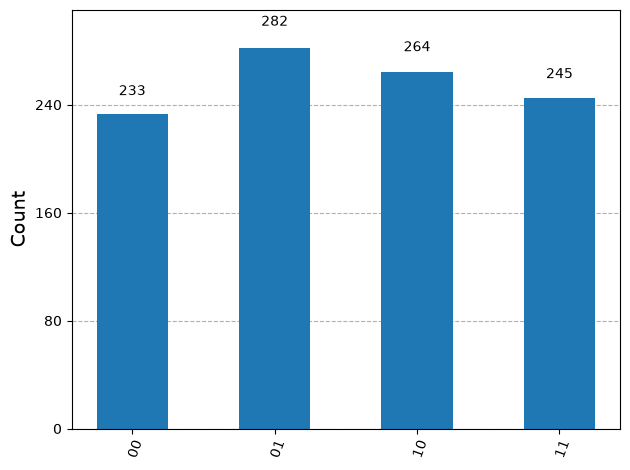

In [23]:
simulator = AerSimulator()

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shot=1000)

plot_histogram(job.result().get_counts())